In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import xgboost as xgb

sns.set_theme(style="whitegrid")
df = pd.read_csv("leptospirosis_unified_panel_qc_2025.csv")

In [6]:
df.shape

(7384, 17)

In [8]:
df.isnull().sum()[df.isnull().sum() > 0]

Series([], dtype: int64)

Class distrubution

In [9]:
df["outbreak_label"].value_counts(normalize=True) * 100

outbreak_label
0    90.912784
1     9.087216
Name: proportion, dtype: float64

### Exploratory Data Analysis (EDA)

Correlation Matrix of Numerical Features

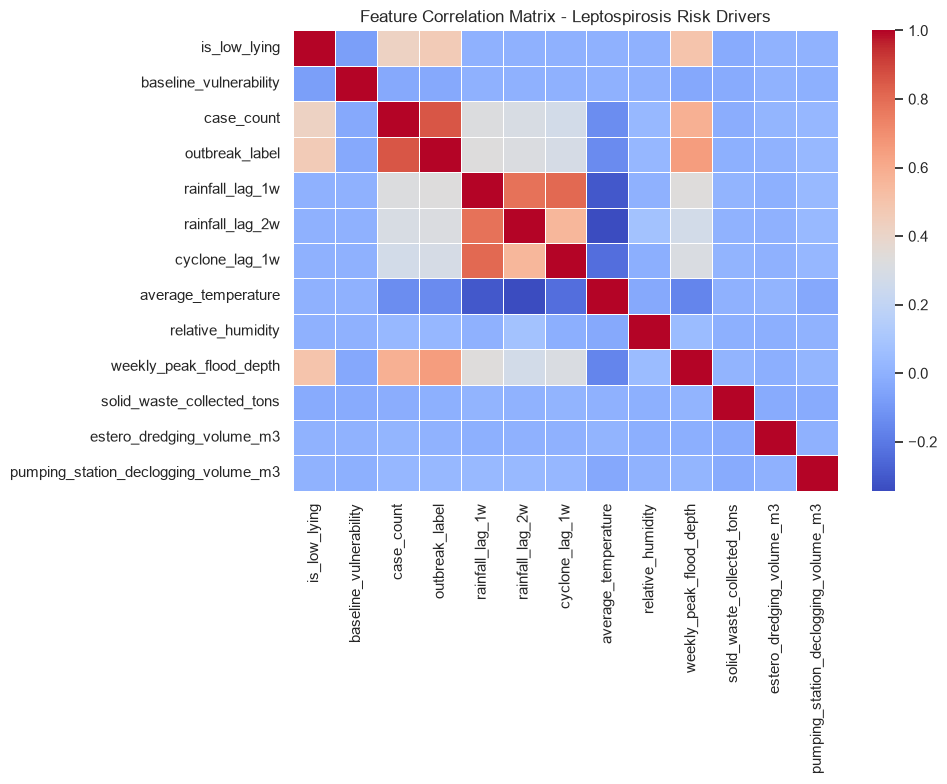

In [11]:
plt.figure(figsize=(10, 8))
numeric_cols = df.select_dtypes(include=[np.number]).columns
corr = df[numeric_cols].corr()
sns.heatmap(
    corr, annot=False, cmap="coolwarm", fmt=".2f", linewidths=0.5, cbar=True
)
plt.title("Feature Correlation Matrix - Leptospirosis Risk Drivers")
plt.tight_layout()
plt.show()

Rainfall Lag vs Outbreak Rate

C:\Users\rmvilla\AppData\Local\Temp\ipykernel_1240\757599503.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="outbreak_label", y="rainfall_lag_1w", data=df, palette="Set2")


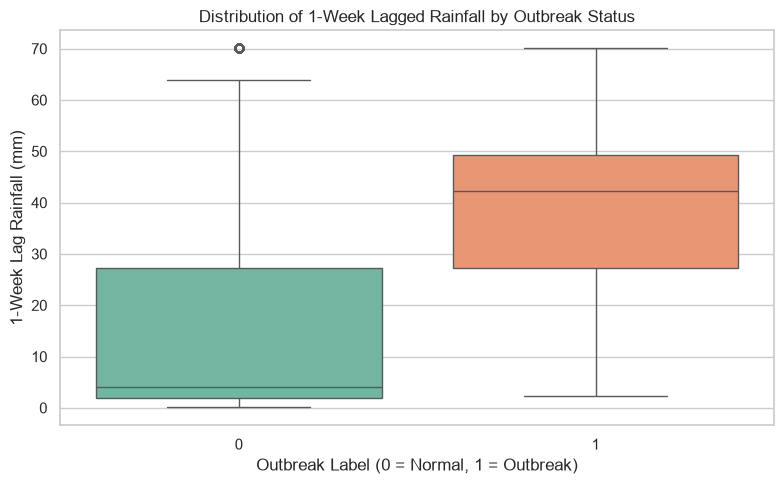

In [13]:
plt.figure(figsize=(8, 5))
sns.boxplot(x="outbreak_label", y="rainfall_lag_1w", data=df, palette="Set2")
plt.title("Distribution of 1-Week Lagged Rainfall by Outbreak Status")
plt.xlabel("Outbreak Label (0 = Normal, 1 = Outbreak)")
plt.ylabel("1-Week Lag Rainfall (mm)")
plt.tight_layout()
plt.show()

### Proprocessing and Feature Engineering

Define feature columns and target

In [14]:
target = "outbreak_label"

# Exclude non-predictive or target leakage columns
drop_cols = [
    target,
    "case_count",
    "epi_week",
    "date_month",
    "location_city",
]
features = [col for col in df.columns if col not in drop_cols]

X = df[features]
y = df[target]

Identify categorical and numerical features

In [15]:
categorical_features = ["location_barangay"]
numerical_features = [
    col for col in features if col not in categorical_features
]

print(f"Numerical Features ({len(numerical_features)}): {numerical_features}")
print(f"Categorical Features ({len(categorical_features)}): {categorical_features}")

Numerical Features (11): ['is_low_lying', 'baseline_vulnerability', 'rainfall_lag_1w', 'rainfall_lag_2w', 'cyclone_lag_1w', 'average_temperature', 'relative_humidity', 'weekly_peak_flood_depth', 'solid_waste_collected_tons', 'estero_dredging_volume_m3', 'pumping_station_declogging_volume_m3']
Categorical Features (1): ['location_barangay']


Train-Test Split (Stratified to maintain class ratio)

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

Preprocessing Pipeline

In [17]:
# One-Hot Encode Barangays, Scale Numerical Variables
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            categorical_features,
        ),
    ]
)

# Apply preprocessing transformations
X_train_transformed = preprocessor.fit_transform(X_train)
X_test_transformed = preprocessor.transform(X_test)

# Retrieve feature names after one-hot encoding for feature importance later
cat_encoder = preprocessor.named_transformers_["cat"]
encoded_cat_features = list(cat_encoder.get_feature_names_out(categorical_features))
all_feature_names = numerical_features + encoded_cat_features

### Model Training

Training an XGBoost Model

In [18]:
# Calculate scale_pos_weight to handle class imbalance (ratio of negative to positive classes)
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
scale_weight = neg_count / pos_count

model = xgb.XGBClassifier(
    n_estimators=150,
    max_depth=5,
    learning_rate=0.05,
    scale_pos_weight=scale_weight,
    random_state=42,
    eval_metric="logloss",
)

model.fit(X_train_transformed, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


### Model Evaluation

In [19]:
y_pred = model.predict(X_test_transformed)
y_prob = model.predict_proba(X_test_transformed)[:, 1]

# Print Performance Metrics
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

roc_auc = roc_auc_score(y_test, y_prob)
print(f"ROC-AUC Score: {roc_auc:.4f}")

# Confusion Matrix Plot
plt.figure(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title(f"Confusion Matrix (ROC-AUC = {roc_auc:.2f})")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.savefig("evaluation_confusion_matrix.png", dpi=300)
plt.close()


Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.94      0.97      1343
           1       0.62      0.97      0.76       134

    accuracy                           0.94      1477
   macro avg       0.81      0.96      0.86      1477
weighted avg       0.96      0.94      0.95      1477

ROC-AUC Score: 0.9756


### Top 10 Feature Importances Plot

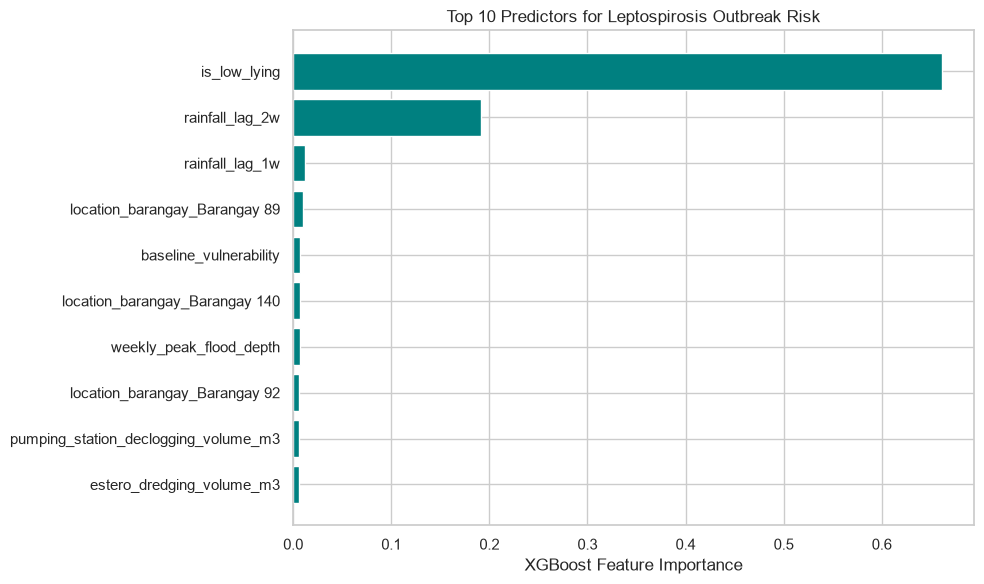

In [21]:
importances = model.feature_importances_
top_indices = np.argsort(importances)[-10:]

plt.figure(figsize=(10, 6))
plt.barh(range(len(top_indices)), importances[top_indices], color="teal")
plt.yticks(range(len(top_indices)), [all_feature_names[i] for i in top_indices])
plt.xlabel("XGBoost Feature Importance")
plt.title("Top 10 Predictors for Leptospirosis Outbreak Risk")
plt.tight_layout()
plt.show()